# Individuell uppgift - Hälsostudie, Del 2

Fördjupning och pipeline: analysen struktureras i en klass och utökas med linjär regression.

### Mål
1. Beskriva hur systoliskt blodtryck samvarierar med ålder (enkel linjär regression).
2. Undersöka om blodtryckets samband med rökning kvarstår när ålder, BMI och kön tas med (multipel regression).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from health_analyzer import HealthAnalyzer

analyzer = HealthAnalyzer("data/health_study_dataset.csv")

np.random.seed(42)

# Inställningar för diagram
plt.rcParams.update({
    "figure.figsize": (8, 5),
    "figure.constrained_layout.use": True,
    "axes.titlesize": 16,
    "axes.labelsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=["royalblue", "darkorange", "seagreen"]),
})

### Datakontroll och nya variabler

Datan kontrolleras och tre variabler skapas inför regressionen: `bmi`, `smoker_yes` och `sex_male`.

In [2]:
analyzer.check_data()

analyzer.add_bmi()
analyzer.add_smoker_yes()
analyzer.add_sex_male()

display(analyzer.df[["bmi", "smoker_yes", "sex_male"]].describe().round(2))

bmi = analyzer.df["bmi"]
print(f"Lägsta BMI: {bmi.min():.1f}, högsta BMI: {bmi.max():.1f}")
print(f"Antal deltagare med BMI < 16: {(bmi < 16).sum()}")

Antal rader och kolumner: (800, 9)
Saknade värden: 0
Antal dubbletter av id: 0
Antal dubbletter av rader (exklusive id): 0
Värden i sex: ['F', 'M']
Värden i smoker: ['No', 'Yes']
Värden i disease: [0, 1]


,bmi,smoker_yes,sex_male
count,800.00,800.00,800.0
mean,24.93,0.27,0.5
std,4.66,0.44,0.5
min,12.63,0.00,0.0
25%,21.92,0.00,0.0
50%,24.70,0.00,0.0
75%,28.01,1.00,1.0
max,40.14,1.00,1.0


Lägsta BMI: 12.6, högsta BMI: 40.1
Antal deltagare med BMI < 16: 23


- Inga saknade värden eller dubbletter, och de kodade variablerna stämmer med de ursprungliga kategorierna.
- - BMI har medelvärde ca 24,9 men spänner från 12,6 till 40,1. Värden under 16 räknas som kraftig undervikt (källa: https://www.kostguiden.se/bmi-tabell/), och 23 deltagare ligger under den nivån, vilket kan tyda på orealistiska värden. De tas inte bort eftersom inget tyder på ett dokumenterat fel, men regressionens resultat tolkas med den osäkerheten i åtanke.

### Enkel linjär regression: blodtryck och ålder

Modellen är ŷ = b₀ + b₁ · ålder, där ŷ är det förutsagda systoliska blodtrycket, b₀ är interceptet och b₁ är lutningen, dvs den genomsnittliga förändringen i blodtryck per år. Koefficienterna väljs så att summan av de kvadrerade residualerna (y − ŷ, skillnaden mellan verkligt och förutsagt värde) blir så liten som möjligt. Modellen anpassas med scikit-learn.

In [3]:
result = analyzer.fit_linear_regression(["age"])

slope = result["coefficients"]["age"]
intercept = result["intercept"]
r2 = result["r2"]

print(f"Intercept: {intercept:.2f} mmHg")
print(f"Lutning: {slope:.3f} mmHg per år ({slope * 10:.2f} mmHg per 10 år)")
print(f"R²: {r2:.3f}")

Intercept: 122.68 mmHg
Lutning: 0.536 mmHg per år (5.36 mmHg per 10 år)
R²: 0.369


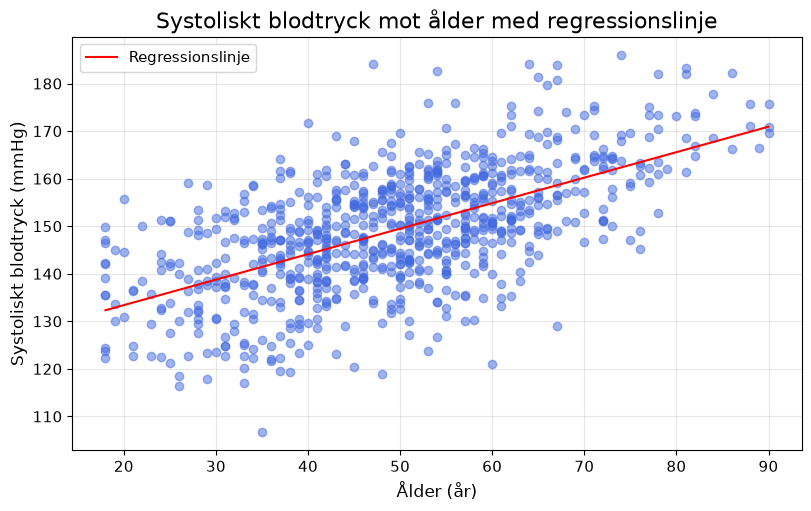

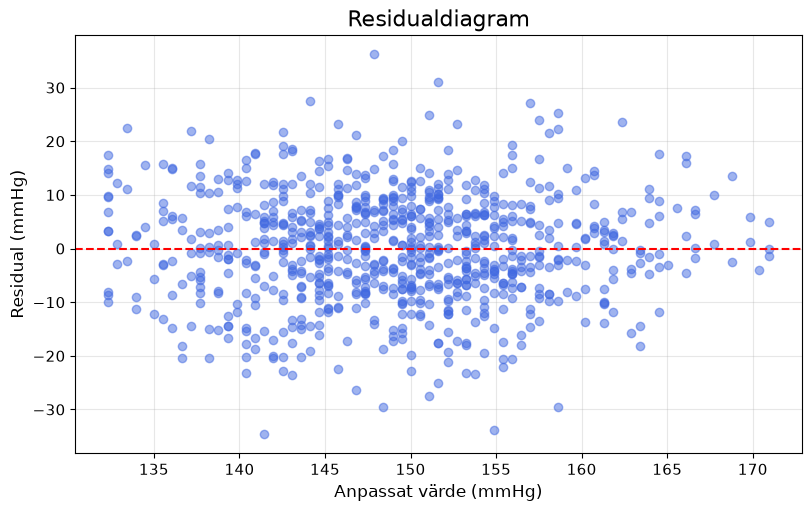

In [4]:
analyzer.plot_fit("age", result)
analyzer.plot_residuals(result)

- Blodtrycket ökar i genomsnitt med ca 0,54 mmHg per år, eller ca 5,4 mmHg per 10 år. R² ≈ 0,37 betyder att ålder förklarar ca 37 % av variationen i blodtryck i detta dataset, så en stor del av variationen beror på andra faktorer.
- Residualdiagrammet visar ett oregelbundet moln runt noll utan ett tydligt mönster, vilket tyder på att en rät linje är en rimlig modell.
- Resultatet beskriver ett samband men visar inte att ålder orsakar högre blodtryck. Modellen är en enkel baslinje som anpassats och utvärderats på samma data, så R² säger inget om hur väl den skulle förutsäga nya individer.

### Multipel linjär regression

Modellen utökas med BMI, rökning och kön:

ŷ = b₀ + b₁ · ålder + b₂ · BMI + b₃ · rökare + b₄ · man

Syftet är att undersöka om blodtryckets samband med rökning kvarstår när ålder, BMI och kön hålls konstanta. Varje koefficient visar den genomsnittliga förändringen i blodtryck när variabeln ökar med en enhet och övriga variabler hålls konstanta (för rökare och man är det skillnaden mellan grupperna). Konfidensintervallen beräknas med bootstrap: raderna dras med återläggning, modellen anpassas om 2000 gånger, och intervallet utgörs av percentilerna 2,5 och 97,5.

In [5]:
predictors = ["age", "bmi", "smoker_yes", "sex_male"]
result_multiple = analyzer.fit_linear_regression(predictors)
intercept_multiple = result_multiple["intercept"]
r2_multiple = result_multiple["r2"]

np.random.seed(42)
coefficient_table = analyzer.bootstrap_coefficients(predictors)

print(f"Intercept: {intercept_multiple:.2f} mmHg")
print(f"R²: {r2_multiple:.3f} (enkel regression: {r2:.3f})")
display(coefficient_table.round(3))

Intercept: 112.23 mmHg
R²: 0.397 (enkel regression: 0.369)


,Koefficient,Nedre gräns,Övre gräns
age,0.540,0.493,0.587
bmi,0.365,0.221,0.509
smoker_yes,-0.304,-1.857,1.270
sex_male,2.468,1.113,3.877


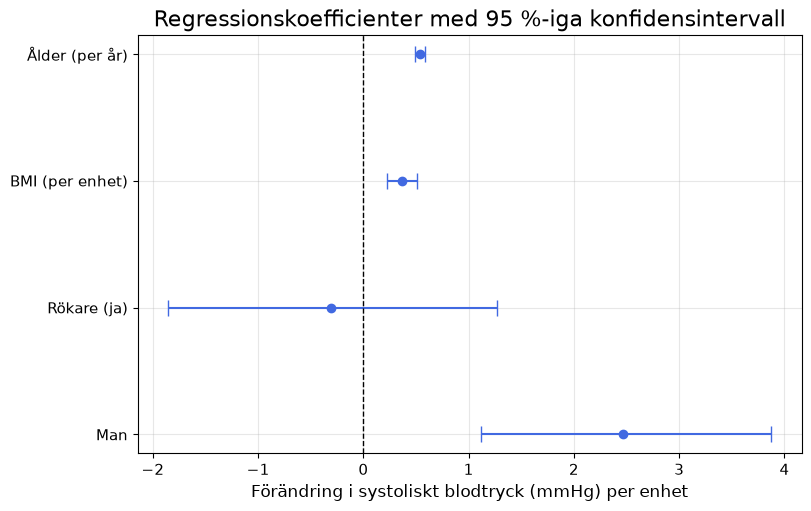

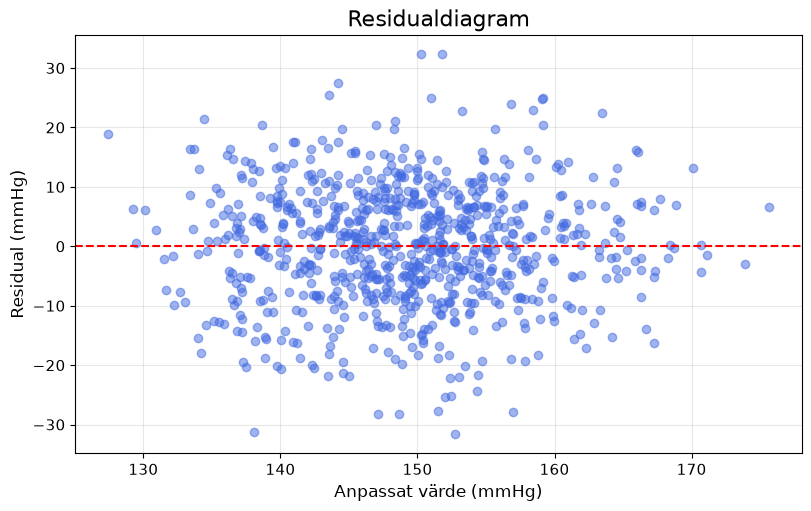

In [6]:
analyzer.plot_coefficients(coefficient_table, labels=["Ålder (per år)", "BMI (per enhet)", "Rökare (ja)", "Man"])
analyzer.plot_residuals(result_multiple)

- Efter justering för ålder, BMI och kön är koefficienten för rökning ca −0,3 mmHg, med ett intervall (ca −1,9 till +1,3 mmHg) som innehåller 0. Resultatet stämmer med hypotesprövningen i del 1: inga belägg har hittats för att rökare har högre blodtryck, och även intervallets övre gräns ligger långt under 5 mmHg.
- Blodtrycket ökar med ålder (ca 0,54 mmHg per år) och BMI (ca 0,37 mmHg per BMI-enhet), och män har i genomsnitt ca 2,5 mmHg högre blodtryck än kvinnor. Intervallen för dessa tre ligger helt över noll.
- R² ökar bara från 0,37 till 0,40, så största delen av variationen förklaras fortfarande inte av modellen. På residualdiagrammet ligger residualerna oregelbundet utspridda runt noll. 
- Resultaten beskriver samband och inte orsakssamband, och modellen är anpassad och utvärderad på samma data. Analyserna är utforskande, så intervallen är inte justerade för att flera koefficienter granskas samtidigt.